# Example EODs at different distances to the nearest fish (4-fish recordings, Kaden masks)

Copy of `EOD_clean_emitter_set_4fish_kaden.ipynb` with two rules changed: the emitter is no longer isolated but has another fish
at a given distance, and the dominance rule is replaced by a shape rule on the 3 loudest pairs. Five videos of 2024-02-20 (05_52_55,
06_52_55, 11_12_57, 15_16_23, 19_16_25).

An EOD is given to fish f, at distance bin [lo, hi), when **all** of these hold:
1. **good masks**: the frame passes the mask QC for all four fish (`mask_qc_good_frames.csv`);
2. **nearest fish at lo–hi cm** (*changed*): the smallest distance between f's mask midline and any other fish's midline is in
   [0, 2), [2, 5) or [5, 10) cm. Distance uses all 101 midline points (the original used every 5th point, which overestimates
   small gaps);
3. **shape**: f has the lowest shape L2 of the four fish (my model, unit current, each pattern scaled to max |v| = 1 over all
   10 pairs; main EOD phase): the `fish | mine, shape` assignment;
4. **recorded amplitude on f's nearest pairs**: f's 2 nearest electrode pairs (distance from f's midline to the nearer pole of
   each pair) are the 2 pairs with the largest recorded |V|, with the sign f's model predicts on both;
5. **shape on the 3 loudest pairs** (*replaces "other fish weaker there"*): on the 3 pairs with the largest recorded |V|, every
   other fish's L2 is ≥ 2× f's. Same scaling as rule 3 (recording and each model scaled to max |v| = 1 over all 10 pairs), with
   the error summed over those 3 pairs only.

The recorded pattern is the main phase (all 10 pairs at the sample of the largest |V|); the model is `mine_unit_current`.

From the EODs that pass, **24 per fish and distance bin** are picked (seed 0). The picks cycle over the pair with the largest
recorded |V| (rarest first), so the loudest pair varies as much as the passing EODs allow. Within one loudest pair the videos
take turns, and picks from one video are at least 100 frames apart. One PDF per fish × distance bin (12 PDFs) in
`results/eod_assign_4fish_kaden/good_mask_example_field_frames/`. A last check recomputes every rule for every picked EOD straight
from the files.

Two more sets follow, one PDF per fish × distance bin in each:
- **best cases** (`best_lowest_L2/`): of the EODs passing rules 1–5, the 24 with the lowest shape L2 of the emitter;
- **uncertain cases** (`uncertain_highest_L2/`): good masks and the same distance bins plus a 4th one, nearest fish ≥ 10 cm
  (isolated, as in the original clean set), but rule 5 fails (some other fish's
  top-3 L2 is < 2× that of the lowest-L2 fish). The 24 with the highest shape L2 of the lowest-L2 fish. Rule 4 is not
  required here.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from matplotlib.backends.backend_pdf import PdfPages
from io_utils import load_masks
from eod_assign import load_electrode_pairs, recorded_pair_traces_all
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
OUT = f'{BASE}/good_mask_example_field_frames'; os.makedirs(f'{OUT}/per_frame', exist_ok=True)
RECS = ['05_52_55', '06_52_55', '11_12_57', '15_16_23', '19_16_25']
KADEN = 'data/track_Kaden/results_{t}_full/video2024-02-20T{t}/outputs/video2024-02-20T{t}.pkl'
ELECTRODES = 'data/electrodes/electrodes_signed_px_coord_4-fish.csv'
EL = pd.read_csv(ELECTRODES).sort_values('pair').reset_index(drop=True)
PIDS = [p for p, _, _ in load_electrode_pairs(ELECTRODES, P)]
PX_CM = P / 60
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
L_CM = {'A': 15.65, 'B': 13.10, 'C': 9.82, 'D': 8.51}
BINS = [(0, 2), (2, 5), (5, 10)]                    # distance from the emitter's midline to the nearest other fish's midline, cm
K_NEAR, K_TOP, L2_RATIO, N_PER_PDF, MIN_DF = 2, 3, 2, 24, 100
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
ELXY = np.concatenate([EL[['y1', 'x1']].to_numpy(float), EL[['y2', 'x2']].to_numpy(float)]) / PX_CM   # (20, row/col) cm


def midline_gaps(xy, chunk=500):
    """(n, 4, 4) minimum distance between the full midlines (all 101 points) of every two fish, cm."""
    n = len(xy); G = np.full((n, 4, 4), np.inf)
    x32 = xy.astype(np.float32)
    for s in range(0, n, chunk):
        c = x32[s:s + chunk]
        for f in range(4):
            for h in range(f + 1, 4):
                d = np.sqrt(((c[:, f, :, None] - c[:, h, None]) ** 2).sum(-1)).min((1, 2))
                G[s:s + chunk, f, h] = G[s:s + chunk, h, f] = d
    return G


rows = []
for t in RECS:
    A = pd.read_csv(f'{BASE}/{t}/eod_assignments.csv'); z = np.load(f'{BASE}/{t}/predicted_voltages.npz')
    assert (A.Frame.to_numpy() == z['frame']).all()
    good = set(pd.read_csv(f'{BASE}/{t}/mask_qc_good_frames.csv').frame)
    mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {int(k): i for i, k in enumerate(mz['frames'])}
    sel = np.flatnonzero([(int(k) in good) and (int(k) in gi) for k in A.Frame])
    A = A.iloc[sel]; R = z['recorded_peak'][sel]; M = z['mine_unit_current'][sel]
    xy = mz['mids'][[gi[int(k)] for k in A.Frame]] * (P - 1) / PX_CM                     # (n, 4, 101, 2) cm
    ok = np.isfinite(xy).all((1, 2, 3)) & np.isfinite(M).all((1, 2))
    A, R, M, xy, sel = A[ok], R[ok], M[ok], xy[ok], sel[ok]; n = len(A); ii = np.arange(n)
    L2 = A[[f'L2 shape {f} | mine' for f in LET]].to_numpy()
    G = midline_gaps(xy)
    top_rec = np.argsort(-np.abs(R), 1)                                                 # pairs by recorded |V|, largest first
    t3 = top_rec[:, :K_TOP]
    Rn = R / np.abs(R).max(1, keepdims=True); Mn = M / np.abs(M).max(2, keepdims=True)  # each scaled to max |v| = 1 over 10 pairs
    L2t = np.linalg.norm(Rn[ii[:, None, None], t3[:, None, :]] - Mn[ii[:, None, None], np.arange(4)[None, :, None], t3[:, None, :]], axis=2)  # (n, 4)
    for f in range(4):
        de = np.linalg.norm(xy[:, f, :, None] - ELXY[None, None], axis=-1).min(1)
        DE = np.minimum(de[:, :10], de[:, 10:])                                             # (n, 10) cm to the nearer pole
        near = np.argsort(DE, 1); nk = near[:, :K_NEAR]
        oth = [h for h in range(4) if h != f]
        rows.append(pd.DataFrame(dict(
            video=t, row=sel, Frame=A.Frame.to_numpy(), fish=LET[f], gap_cm=G[:, f].min(1),
            closest_fish=[LET[h] for h in G[:, f].argmin(1)],
            shape_pick=A['fish | mine, shape'].fillna('').to_numpy(), L2_fish=L2[:, f], L2_next_best=np.sort(L2[:, oth], 1)[:, 0],
            nearest_pair=near[:, 0] + 1, second_pair=near[:, 1] + 1, dist_nearest_cm=DE[ii, near[:, 0]], dist_second_cm=DE[ii, near[:, 1]],
            rec_top_pair=top_rec[:, 0] + 1, rec_top3_pairs=[','.join(map(str, r[:3] + 1)) for r in top_rec], rec_max_V=np.abs(R).max(1),
            rec_top_is_nearest=[set(a[:K_NEAR]) == set(b[:K_NEAR]) for a, b in zip(near, top_rec)],
            sign_ok=(np.sign(R[ii[:, None], nk]) == np.sign(M[ii[:, None], f, nk])).all(1),
            L2top3_fish=L2t[:, f], L2top3_next_best=L2t[:, oth].min(1))))
D = pd.concat(rows, ignore_index=True)
D['L2top3_ratio'] = D.L2top3_next_best / D.L2top3_fish                        # ≥ 2: every other fish's top-3 L2 is ≥ 2× the emitter's
D['gap_bin'] = pd.cut(D.gap_cm, [b[0] for b in BINS] + [BINS[-1][1]], right=False, labels=[f'{a}-{b} cm' for a, b in BINS])

FUNNEL, PASS = {}, []
for lab in D.gap_bin.cat.categories:
    c = {'1. good masks (all fish)': np.ones(len(D), bool)}
    c[f'2. nearest fish {lab}'] = D.gap_bin == lab
    c['3. + lowest shape L2'] = c[f'2. nearest fish {lab}'] & (D.shape_pick == D.fish)
    c['4. + recorded top-2 = 2 nearest pairs, model sign'] = c['3. + lowest shape L2'] & D.rec_top_is_nearest & D.sign_ok
    c[f'5. + top-3 L2 ≤ 1/{L2_RATIO} of every other fish'] = c['4. + recorded top-2 = 2 nearest pairs, model sign'] & (D.L2top3_ratio >= L2_RATIO)
    F = pd.DataFrame({k: D[v].groupby('fish').size() for k, v in c.items()}).T.reindex(columns=list(LET)).fillna(0).astype(int)
    F['all'] = F.sum(1); FUNNEL[lab] = F
    PASS.append(D[list(c.values())[-1]])
PASS = pd.concat(PASS, ignore_index=True)
for lab, F in FUNNEL.items():
    print(f'nearest other fish {lab}: fish-EODs passing each step (cumulative)'); display(F.iloc[1:])
print('passing EODs per fish × distance × recorded top pair:')
display(pd.crosstab([PASS.fish, PASS.gap_bin], PASS.rec_top_pair, margins=True))

nearest other fish 0-2 cm: fish-EODs passing each step (cumulative)


fish,A,B,C,D,all
2. nearest fish 0-2 cm,12698,1768,9586,7132,31184
3. + lowest shape L2,3226,417,2841,2081,8565
"4. + recorded top-2 = 2 nearest pairs, model sign",368,123,388,280,1159
5. + top-3 L2 ≤ 1/2 of every other fish,324,50,321,195,890


nearest other fish 2-5 cm: fish-EODs passing each step (cumulative)


fish,A,B,C,D,all
2. nearest fish 2-5 cm,39417,17343,32654,21929,111343
3. + lowest shape L2,10081,3714,9237,6714,29746
"4. + recorded top-2 = 2 nearest pairs, model sign",1165,906,1256,447,3774
5. + top-3 L2 ≤ 1/2 of every other fish,1076,341,998,386,2801


nearest other fish 5-10 cm: fish-EODs passing each step (cumulative)


fish,A,B,C,D,all
2. nearest fish 5-10 cm,13932,14894,12621,16332,57779
3. + lowest shape L2,4016,2457,3558,5284,15315
"4. + recorded top-2 = 2 nearest pairs, model sign",791,702,992,245,2730
5. + top-3 L2 ≤ 1/2 of every other fish,752,314,673,204,1943


passing EODs per fish × distance × recorded top pair:


rec_top_pair   1    2    3     4     5     6    7   8  9   10   All
fish gap_bin                                                       
A    0-2 cm    0    0    1    85   115   117    0   5  0    1   324
     2-5 cm    0    0    4   135   591   314    6  12  0   14  1076
     5-10 cm   1   15   25    59   426   208    6   7  0    5   752
B    0-2 cm    5    0   38     1     0     1    5   0  0    0    50
     2-5 cm    3    1  147   106     0    42   29   2  0   11   341
     5-10 cm   2    1  116    35     0    86   38   4  0   32   314
C    0-2 cm    2    5   38    72    26   147   13   3  0   15   321
     2-5 cm    7   15   71   319    18   436   42   6  1   83   998
     5-10 cm  10   14  157   183     6   208   18  11  0   66   673
D    0-2 cm    0    3   20    24    46    80    1  11  0   10   195
     2-5 cm    5   36   43    24   102   129   14   6  0   27   386
     5-10 cm  21   26   12    10    43    58    9   7  0   18   204
All           56  116  672  1053  1373  1826  181  74  1  282  5634

## Picking 24 per fish and distance, varying the loudest pair

In [2]:
def pick_varied(g, n, rng):
    """Up to n EODs of g, cycling over the recorded top pair (rarest first in each round) so that it varies as much as the
       passing EODs allow; within a top pair, random order with the videos taking turns; ≥ MIN_DF frames apart within a video."""
    g = g.iloc[rng.permutation(len(g))]
    queues = {}
    for p, gp in g.groupby('rec_top_pair'):
        gp = gp.assign(_turn=gp.groupby('video').cumcount()).sort_values('_turn', kind='stable').drop(columns='_turn')
        queues[p] = [r for _, r in gp.iterrows()]
    order = sorted(queues, key=lambda p: len(queues[p]))
    chosen = []
    while len(chosen) < n and any(queues.values()):
        for p in order:
            if len(chosen) == n: break
            q = queues[p]
            while q:
                r = q.pop(0)
                if any(r.video == c.video and abs(r.Frame - c.Frame) < MIN_DF for c in chosen): continue
                chosen.append(r); break
    return chosen


rng = np.random.default_rng(0)
pick = []
for (f, b), g in PASS.groupby(['fish', 'gap_bin'], observed=True):
    pick += pick_varied(g, N_PER_PDF, rng)
PK = pd.DataFrame(pick).sort_values(['fish', 'gap_bin', 'rec_top_pair', 'video', 'Frame']).reset_index(drop=True)
PK.to_csv(f'{OUT}/example_set.csv', index=False); PASS.to_csv(f'{OUT}/all_passing.csv', index=False)
print(f'{len(PK)} EODs picked; per fish × distance × recorded top pair:')
display(pd.crosstab([PK.fish, PK.gap_bin], PK.rec_top_pair, margins=True))
display(PK[['video', 'Frame', 'row', 'fish', 'gap_cm', 'closest_fish', 'rec_top3_pairs', 'nearest_pair', 'second_pair',
            'L2_fish', 'L2_next_best', 'L2top3_fish', 'L2top3_next_best', 'L2top3_ratio', 'rec_max_V']].round(3))

276 EODs picked; per fish × distance × recorded top pair:


rec_top_pair   1   2   3   4   5   6   7   8  9  10  All
fish gap_bin                                            
A    0-2 cm    0   0   1   7   7   6   0   2  0   1   24
     2-5 cm    0   0   3   4   4   4   2   2  0   5   24
     5-10 cm   1   3   3   3   2   3   3   3  0   3   24
B    0-2 cm    1   0   8   1   0   1   1   0  0   0   12
     2-5 cm    1   1   4   4   0   4   5   1  0   4   24
     5-10 cm   2   1   4   4   0   4   4   1  0   4   24
C    0-2 cm    2   3   3   3   3   2   3   2  0   3   24
     2-5 cm    3   3   2   2   3   2   3   3  1   2   24
     5-10 cm   3   3   2   2   3   2   3   3  0   3   24
D    0-2 cm    0   2   4   4   3   3   1   3  0   4   24
     2-5 cm    3   3   2   3   2   2   3   3  0   3   24
     5-10 cm   3   3   3   3   3   2   3   1  0   3   24
All           19  22  39  40  30  35  31  24  1  35  276

,video,Frame,row,fish,gap_cm,closest_fish,rec_top3_pairs,nearest_pair,second_pair,L2_fish,L2_next_best,L2top3_fish,L2top3_next_best,L2top3_ratio,rec_max_V
0,05_52_55,17707,13742,A,1.196,D,"3,4,9",3,4,0.510,1.368,0.379,0.834,2.203,0.106
1,05_52_55,30031,24914,A,0.416,C,"4,5,9",5,4,0.391,2.202,0.296,1.698,5.735,0.122
2,05_52_55,52397,44633,A,1.502,C,"4,3,10",4,3,0.384,1.648,0.257,1.478,5.752,0.078
3,06_52_55,30457,28198,A,1.327,C,"4,3,10",4,3,0.135,1.493,0.085,0.927,10.858,0.090
4,06_52_55,40492,37212,A,1.728,C,"4,3,10",3,4,0.370,1.805,0.314,1.700,5.405,0.071
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271,15_16_23,50296,50525,D,9.745,A,"7,8,6",7,8,0.682,1.665,0.426,1.259,2.959,0.016
272,05_52_55,29230,24082,D,6.738,B,"8,9,1",8,9,0.122,1.718,0.103,1.139,11.059,0.069
273,05_52_55,19848,15622,D,5.280,A,"10,3,2",3,10,0.299,2.101,0.164,1.438,8.745,0.023
274,15_16_23,15186,15925,D,9.301,A,"10,6,7",6,10,0.113,0.559,0.089,0.492,5.501,0.030


## Data of the picked EODs (masks, midlines, recorded traces, model)

In [3]:
import gc
masks, mids, TR, MM, DN = {}, {}, {}, {}, {}             # masks stored bit-packed (4 fish × 912² per frame would be ~3 MB)

def load_examples(df):
    """masks, midlines, recorded traces, my model and Denis' model of every EOD of df (added to masks, mids, TR, MM, DN).
       Each npz array is read once per video and only copies of the wanted rows are kept (a view would keep the whole array)."""
    for t in df.video.unique():
        g = df[(df.video == t) & ~np.array([(t, int(rw)) in TR for rw in df.row])]
        if not len(g): continue
        mk = load_masks(KADEN.format(t=t), tracking='kaden')
        assert mk.names == tuple(LET), mk.names
        for k in g.Frame.unique(): masks[(t, int(k))] = np.packbits(mk[int(k)])
        del mk
        z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); idx = {int(k): i for i, k in enumerate(z['frames'])}; zm = z['mids']
        for k in g.Frame.unique(): mids[(t, int(k))] = zm[idx[int(k)]] * (P - 1)
        rows = np.unique(g.row.to_numpy())
        keep = set(int(rw) + 1 for rw in rows)                # file lines of these EOD rows (line 0 = header): read only those
        csv = pd.read_csv(f'data/4 fish/Data_4fish_2024-02-20T{t}.csv', usecols=[f'electrode_{p}_time_{i}' for p in PIDS for i in range(1, 26)],
                          skiprows=lambda i: i > 0 and i not in keep)
        assert len(csv) == len(rows)
        Vt = recorded_pair_traces_all(csv, PIDS, 25); del csv
        pv = np.load(f'{BASE}/{t}/predicted_voltages.npz'); fr = pv['frame']; muc = pv['mine_unit_current']
        for k, rw in enumerate(rows): TR[(t, int(rw))] = Vt[k].copy(); MM[(t, int(rw))] = muc[rw].copy()
        # Denis' pipeline on the same EOD rows: signed peak-to-peak recording and predictions, cosine similarity, his pick
        dz = np.load(f'{BASE}/{t}/denis_predicted_voltages.npz'); da = pd.read_csv(f'{BASE}/{t}/denis_assignments.csv')
        assert (dz['frame'] == fr).all() and (da.Frame.to_numpy() == fr).all() and list(dz['letters']) == list(LET)
        rec, pred = dz['recorded_ptp'], dz['predicted_ptp']; sim = da[[f'similarity {f}' for f in LET]].to_numpy(); pick = da['fish | Denis, similarity']
        for rw in rows:
            pk_ = pick.iloc[rw]
            DN[(t, int(rw))] = dict(rec=rec[rw].copy(), pred=pred[rw].copy(), sim=sim[rw].copy(), pick=pk_ if isinstance(pk_, str) else '')
        del z, zm, Vt, pv, muc, dz, da, rec, pred, sim; gc.collect()
get_masks = lambda key: np.unpackbits(masks[key])[:4 * P * P].reshape(4, P, P).astype(bool)
load_examples(PK)
print(f'loaded {len(masks)} frames, {len(TR)} EODs')

loaded 275 frames, 276 EODs


## Check: every rule recomputed for every picked EOD from the files

In [4]:
# Independent re-check of the rules for every picked EOD, straight from the files (no reuse of the table above).
from scipy.spatial.distance import cdist
pairs_rc = {}                                                     # pair -> (pole 1, pole 2) (row, col) cm
for _, e in EL.iterrows(): pairs_rc[int(e.pair)] = (np.array([e.y1, e.x1]) / PX_CM, np.array([e.y2, e.x2]) / PX_CM)

def check(df, rule4=True, rule5_holds=True):
    """Rules 1-3 always; rule 4 if rule4; rule 5 must hold (rule5_holds=True) or must fail (False). Returns the problems."""
    problems = []
    for t, g in df.groupby('video'):
        A = pd.read_csv(f'{BASE}/{t}/eod_assignments.csv'); z = np.load(f'{BASE}/{t}/predicted_voltages.npz')
        good = set(pd.read_csv(f'{BASE}/{t}/mask_qc_good_frames.csv').frame)
        mz = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); gi = {int(k): i for i, k in enumerate(mz['frames'])}
        for _, r in g.iterrows():
            rw, k, f = int(r.row), int(r.Frame), LET.index(r.fish)
            bad = lambda why: problems.append((t, k, rw, r.fish, why))
            if int(A.Frame.iloc[rw]) != k or int(z['frame'][rw]) != k: bad('row/frame mismatch')
            if k not in good: bad('1. frame not in mask QC good frames')
            xy = mz['mids'][gi[k]] * (P - 1) / PX_CM                                   # (4, 101, 2) cm
            gap = min(cdist(xy[f], xy[h]).min() for h in range(4) if h != f)
            lab = r.gap_bin.replace(' cm', '')
            lo, hi = (float(lab[:-1]), np.inf) if lab.endswith('+') else map(float, lab.split('-'))
            if not lo <= gap < hi: bad(f'2. nearest fish {gap:.2f} cm, not in {r.gap_bin}')
            R = z['recorded_peak'][rw]; M = z['mine_unit_current'][rw]
            V = TR[(t, rw)]; Rt = V[:, np.abs(V).max(0).argmax()]
            if not np.allclose(Rt, R, rtol=1e-6, atol=1e-9): bad('recorded_peak differs from the main phase of the traces')
            Rn = R / np.abs(R).max(); Mn = M / np.abs(M).max(1, keepdims=True)
            L2 = np.linalg.norm(Rn - Mn, axis=1)
            if L2.argmin() != f or A['fish | mine, shape'].iloc[rw] != r.fish: bad('3. not the lowest shape L2')
            if not np.isclose(L2[f], r.L2_fish): bad('shape L2 differs from the table')
            top = list(np.argsort(-np.abs(R)) + 1)
            if rule4:
                dist = {p: min(np.linalg.norm(xy[f] - q, axis=1).min() for q in poles) for p, poles in pairs_rc.items()}
                near2 = sorted(dist, key=dist.get)[:2]
                if set(near2) != set(top[:2]): bad(f'4. nearest pairs {near2} ≠ recorded top-2 {top[:2]}')
                if any(np.sign(R[p - 1]) != np.sign(M[f, p - 1]) for p in near2): bad('4. sign differs from the model')
            t3 = np.array(top[:3]) - 1
            l2t = np.linalg.norm(Rn[t3] - Mn[:, t3], axis=1)
            holds = all(l2t[h] >= L2_RATIO * l2t[f] for h in range(4) if h != f)
            if holds != rule5_holds: bad(f'5. top-3 L2 {np.round(l2t, 3)}: rule {"fails" if rule5_holds else "holds"}')
        del A, z, mz
    return problems

problems = check(PK)
if problems: display(pd.DataFrame(problems, columns=['video', 'Frame', 'row', 'fish', 'problem']))
else: print(f'all {len(PK)} picked EODs pass rules 1-5 when re-checked from the files')
assert not problems

all 276 picked EODs pass rules 1-5 when re-checked from the files


## One figure per picked EOD

- **tank** (top left): Kaden's masks of that frame, each fish in its colour; the emitter in a dashed box; electrodes (+ filled,
  − open, pair number at the + pole); the emitter's 2 nearest pairs joined by a line; **black line: where the emitter's midline is
  closest to the nearest fish** (rule 2).
- **zooms** (top right): each fish's mask with its midline (head = dot); other fish and their midlines grey; 2 cm scale bar.
- **shape** (bottom left): main phase, recording and every fish's model each scaled to max |v| = 1 (legend: shape L2 over all 10
  pairs, rule 3); grey bands: the 3 largest recorded pairs.
- **L2 on the 3 largest pairs** (bottom middle): rule 5; dashed line at 2× the emitter's, every other bar must reach it.
- **recorded traces** (bottom right): the 25 samples of all 10 pairs (demeaned, volts); the 3 largest pairs in the emitter's
  colour; dotted line: main-phase sample.

PDF pages are sorted by loudest pair. The first figure of fish A at each distance is shown here; all figures are in `per_frame/`.

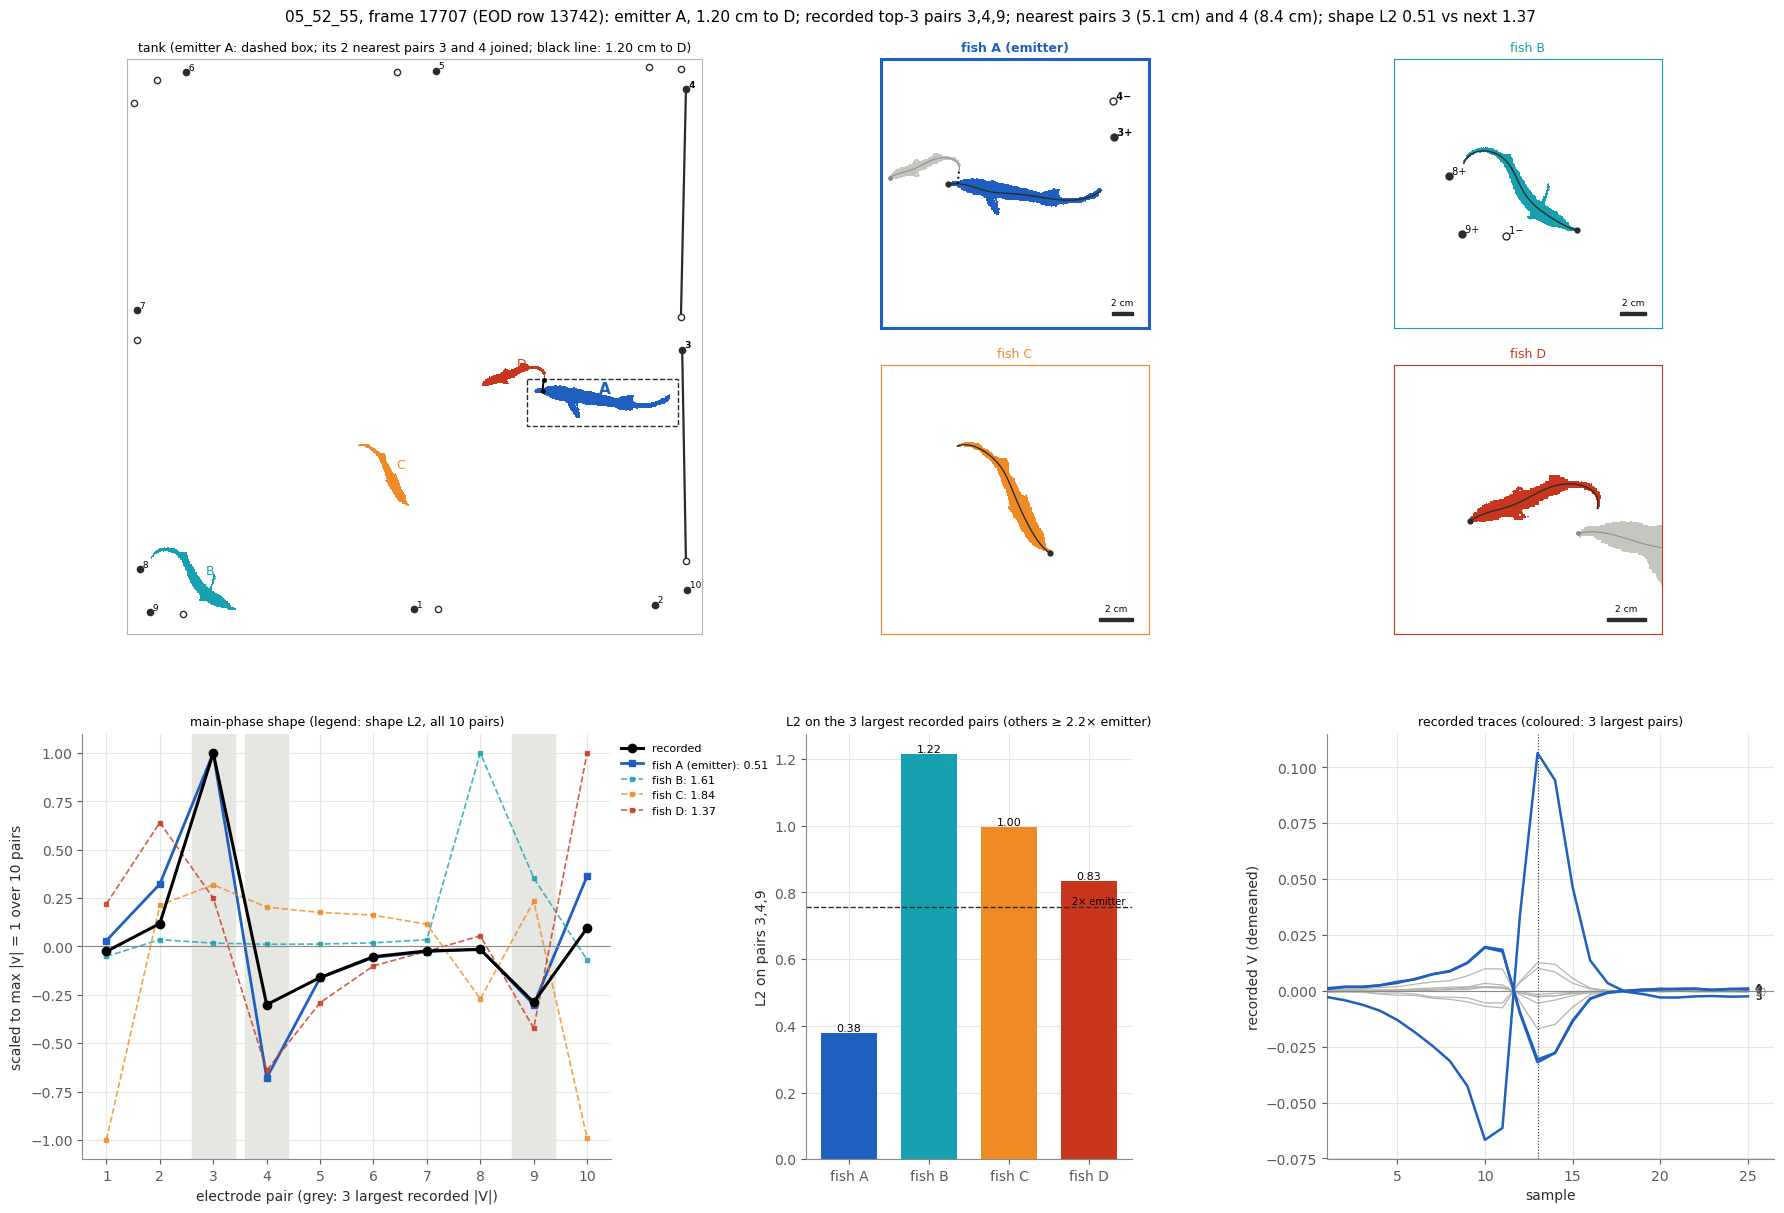

fish A, nearest fish 0-2 cm: 24 figures (top pairs [3, 4, 5, 6, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_A_nearest_fish_0-2cm.pdf


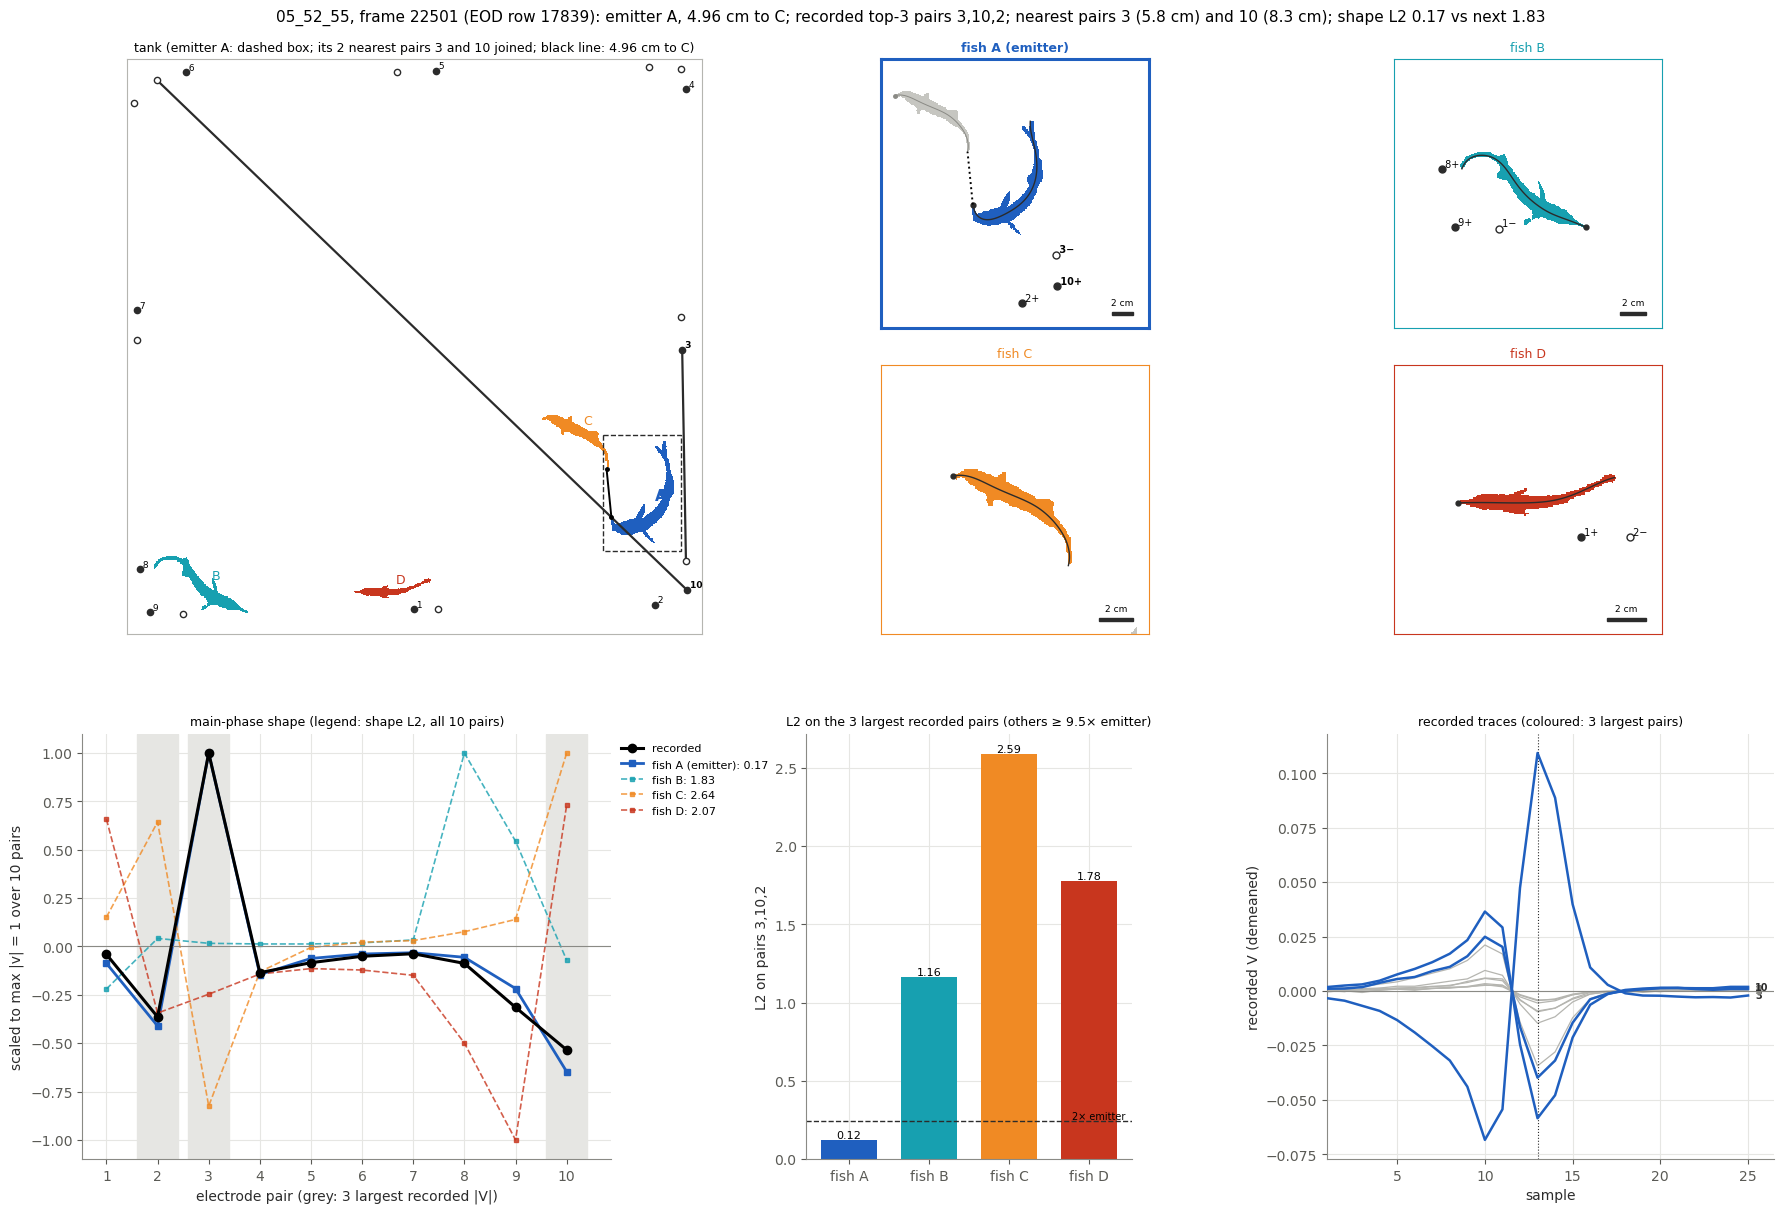

fish A, nearest fish 2-5 cm: 24 figures (top pairs [3, 4, 5, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_A_nearest_fish_2-5cm.pdf


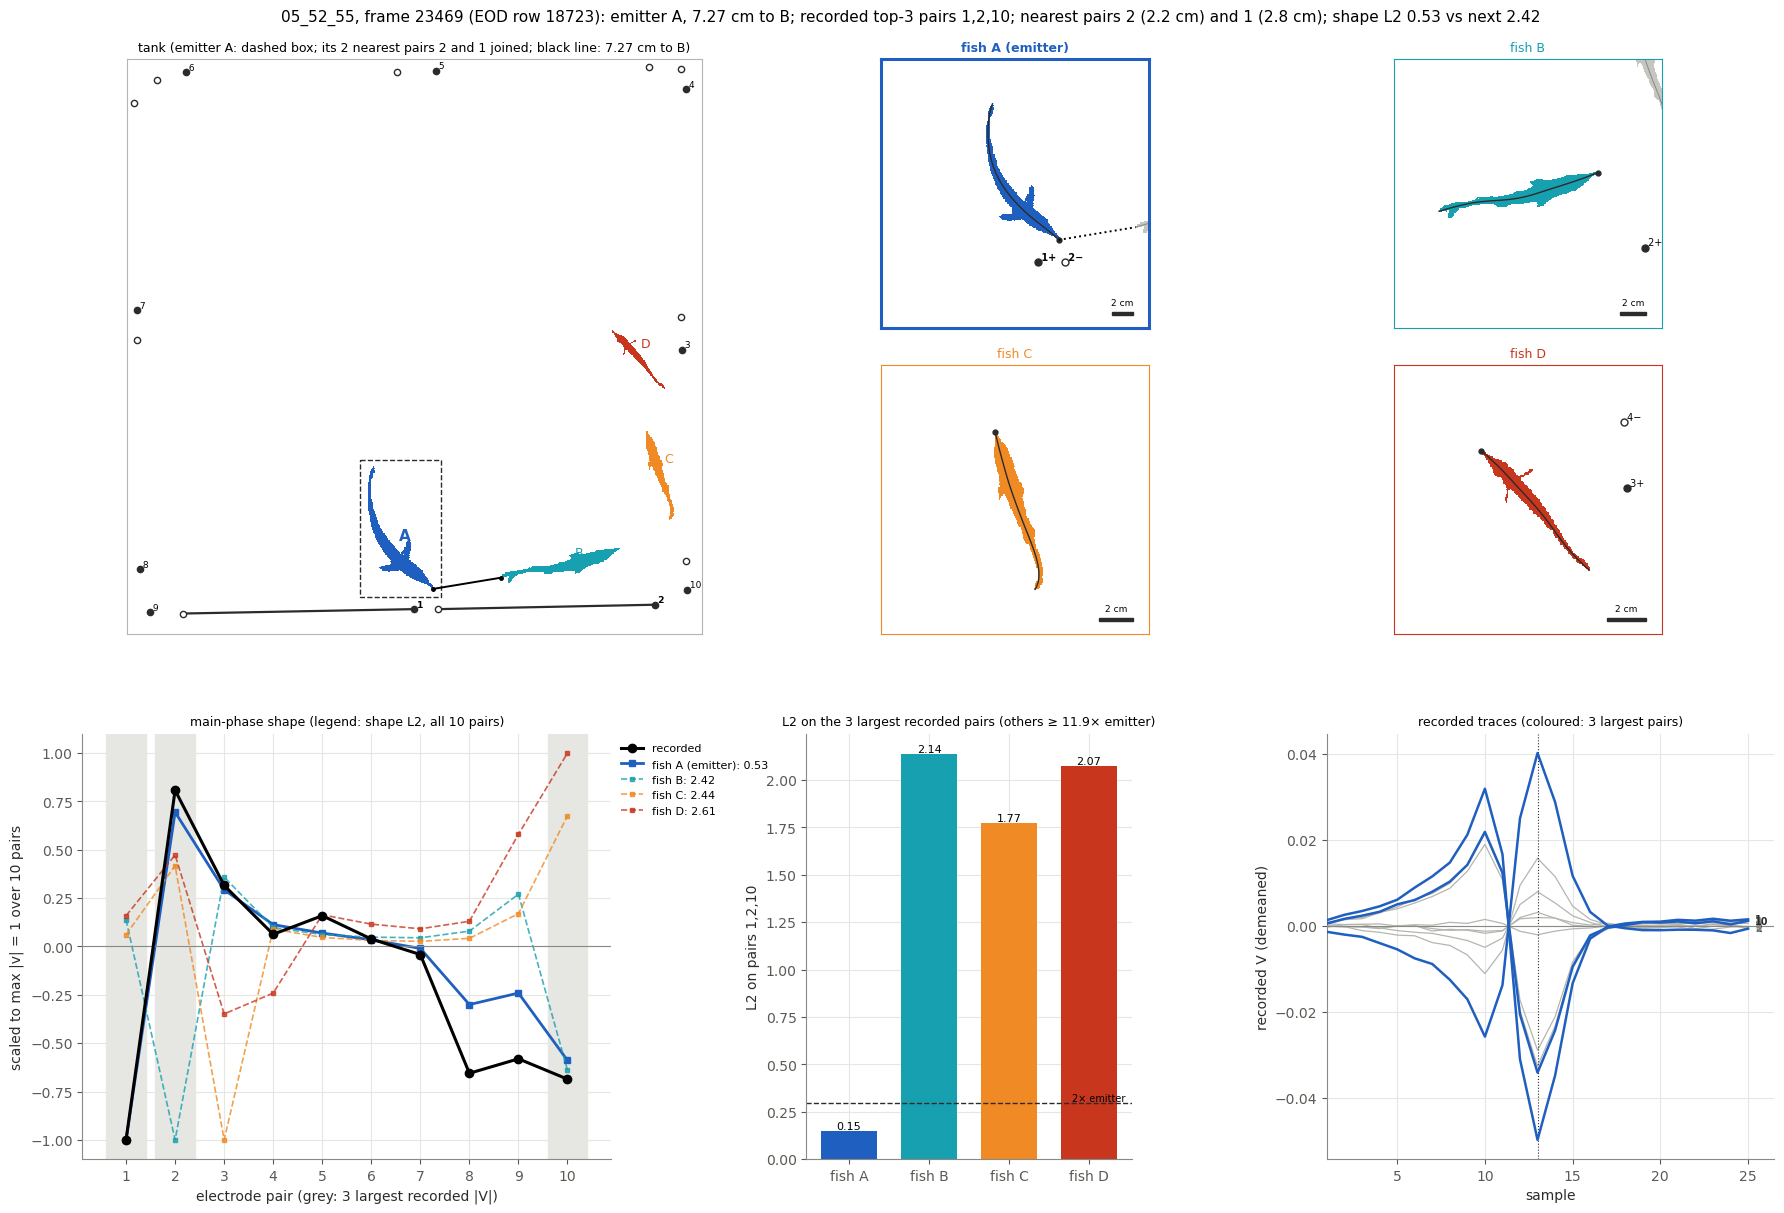

fish A, nearest fish 5-10 cm: 24 figures (top pairs [1, 2, 3, 4, 5, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_A_nearest_fish_5-10cm.pdf


fish B, nearest fish 0-2 cm: 12 figures (top pairs [1, 3, 4, 6, 7]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_B_nearest_fish_0-2cm.pdf


fish B, nearest fish 2-5 cm: 24 figures (top pairs [1, 2, 3, 4, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_B_nearest_fish_2-5cm.pdf


fish B, nearest fish 5-10 cm: 24 figures (top pairs [1, 2, 3, 4, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_B_nearest_fish_5-10cm.pdf


fish C, nearest fish 0-2 cm: 24 figures (top pairs [1, 2, 3, 4, 5, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_C_nearest_fish_0-2cm.pdf


fish C, nearest fish 2-5 cm: 24 figures (top pairs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_C_nearest_fish_2-5cm.pdf


fish C, nearest fish 5-10 cm: 24 figures (top pairs [1, 2, 3, 4, 5, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_C_nearest_fish_5-10cm.pdf


fish D, nearest fish 0-2 cm: 24 figures (top pairs [2, 3, 4, 5, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_D_nearest_fish_0-2cm.pdf


fish D, nearest fish 2-5 cm: 24 figures (top pairs [1, 2, 3, 4, 5, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_D_nearest_fish_2-5cm.pdf


fish D, nearest fish 5-10 cm: 24 figures (top pairs [1, 2, 3, 4, 5, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/fish_D_nearest_fish_5-10cm.pdf


In [5]:
def draw_electrodes(ax, hit_pairs, lim=None, fs=6.5, ms=4.5):
    for _, e in EL.iterrows():
        pp = (e.x1, e.y1) if str(e.pol1).strip() == '+' else (e.x2, e.y2)
        mm_ = (e.x2, e.y2) if str(e.pol1).strip() == '+' else (e.x1, e.y1)
        hit = int(e.pair) in hit_pairs
        if lim is None and hit: ax.plot([pp[0], mm_[0]], [pp[1], mm_[1]], color='#2b2b2b', lw=1.6, zorder=2)
        for pt, filled in ((pp, True), (mm_, False)):
            if lim is not None and not (lim[0] <= pt[0] <= lim[1] and lim[2] <= pt[1] <= lim[3]): continue
            ax.plot(*pt, 'o', ms=ms, mfc='#2b2b2b' if filled else 'white', mec='#2b2b2b', mew=1, zorder=3)
            if filled or lim is not None:
                ax.text(pt[0], pt[1], f' {int(e.pair)}' + ('' if lim is None else ('+' if filled else '−')), fontsize=fs,
                        color='#000000', fontweight='bold' if hit else 'normal', va='bottom', zorder=3)

def closest_points(ml, f, h):
    """the two closest points (row, col px) of the midlines of fish f and h"""
    d = np.linalg.norm(ml[f][:, None] - ml[h][None], axis=-1); i, j = np.unravel_index(d.argmin(), d.shape)
    return ml[f][i], ml[h][j]

def tank(ax, r, m, ml, near):
    img = np.ones((P, P, 3))
    for j, f in enumerate(LET): img[m[j]] = to_rgb(FISH_COL[f])
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    for j, f in enumerate(LET):
        if m[j].any():
            yy, xx = np.nonzero(m[j])
            ax.text(xx.mean() + 18, yy.mean() - 18, f, fontsize=11 if f == r.fish else 9, color=FISH_COL[f],
                    fontweight='bold' if f == r.fish else 'normal', ha='center', va='center')
    j = LET.index(r.fish)
    if m[j].any():
        yy, xx = np.nonzero(m[j])
        ax.add_patch(Rectangle((xx.min() - 12, yy.min() - 12), xx.max() - xx.min() + 24, yy.max() - yy.min() + 24, fill=False, ec='#2b2b2b', lw=1, ls='--'))
    a, b = closest_points(ml, j, LET.index(r.closest_fish))                        # where the nearest fish is closest
    ax.plot([a[1], b[1]], [a[0], b[0]], color='#000000', lw=1.4, zorder=4)
    for q in (a, b): ax.plot(q[1], q[0], 'o', ms=2.5, color='#000000', zorder=4)
    draw_electrodes(ax, near)
    ax.set(xlim=(0, P), ylim=(P, 0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color('#b5b5b0')
    ax.set_title(f'tank (emitter {r.fish}: dashed box; its 2 nearest pairs {near[0]} and {near[1]} joined; '
                 f'black line: {r.gap_cm:.2f} cm to {r.closest_fish})', fontsize=9)

def zoom(ax, r, m, f, ml, near):
    j = LET.index(f)
    if not m[j].any():
        ax.axis('off'); ax.text(0.5, 0.5, f'fish {f}: no mask', ha='center', transform=ax.transAxes); return
    yy, xx = np.nonzero(m[j]); cy, cx = yy.mean(), xx.mean(); h = 0.8 * L_CM[f] * PX_CM
    x0, x1, y0, y1 = cx - h, cx + h, cy - h, cy + h
    img = np.ones((P, P, 3))
    for jj, g in enumerate(LET): img[m[jj]] = to_rgb(FISH_COL[g]) if g == f else (0.78, 0.78, 0.76)
    ax.imshow(img, origin='upper', extent=(-0.5, P - 0.5, P - 0.5, -0.5), interpolation='nearest')
    for jj in range(4):                                                          # every midline in view (others grey)
        if np.isfinite(ml[jj]).all():
            c = '#2b2b2b' if jj == j else '#8a8a85'
            ax.plot(ml[jj][:, 1], ml[jj][:, 0], color=c, lw=1 if jj == j else 0.7); ax.plot(ml[jj][-1, 1], ml[jj][-1, 0], 'o', ms=3.5 if jj == j else 2.5, color=c)
    if f == r.fish:
        a, b = closest_points(ml, j, LET.index(r.closest_fish))
        ax.plot([a[1], b[1]], [a[0], b[0]], color='#000000', lw=1.4, ls=':', zorder=4)
    draw_electrodes(ax, near if f == r.fish else [], lim=(x0, x1, y0, y1), fs=7, ms=5)
    sb = 2 * PX_CM
    ax.add_patch(Rectangle((x1 - 0.06 * 2 * h - sb, y1 - 0.06 * 2 * h), sb, 0.012 * 2 * h, color='#2b2b2b'))
    ax.text(x1 - 0.06 * 2 * h - sb / 2, y1 - 0.075 * 2 * h, '2 cm', fontsize=6.5, ha='center', va='bottom')
    ax.set(xlim=(x0, x1), ylim=(y1, y0), xticks=[], yticks=[], aspect='equal'); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(FISH_COL[f]); sp.set_linewidth(2.2 if f == r.fish else 0.8)
    ax.set_title(f"fish {f}{' (emitter)' if f == r.fish else ''}", fontsize=9, fontweight='bold' if f == r.fish else 'normal', color=FISH_COL[f])

def bottom(axs_, axl, axt, r):
    V = TR[(r.video, int(r.row))]; Mf = MM[(r.video, int(r.row))]
    ts = int(np.abs(V).max(0).argmax()); R = V[:, ts]; x = np.arange(1, 11)
    top3 = [int(p) for p in r.rec_top3_pairs.split(',')]
    Rn = R / np.abs(R).max(); Mn = Mf / np.abs(Mf).max(1, keepdims=True)
    axs_.plot(x, Rn, '-o', color='#000000', lw=2.2, ms=6, label='recorded', zorder=5)
    for j, f in enumerate(LET):
        e = f == r.fish; l2 = np.linalg.norm(Rn - Mn[j])
        axs_.plot(x, Mn[j], marker='s', color=FISH_COL[f], lw=2 if e else 1.2, ms=5 if e else 3.5, ls='-' if e else '--', alpha=1 if e else 0.8,
                  label=f'fish {f}{" (emitter)" if e else ""}: {l2:.2f}')
    for p in top3: axs_.axvspan(p - 0.4, p + 0.4, color='#e6e6e3', zorder=0)
    axs_.axhline(0, color='#8a8a85', lw=0.8)
    axs_.set(xticks=x, xlabel='electrode pair (grey: 3 largest recorded |V|)', ylabel='scaled to max |v| = 1 over 10 pairs')
    axs_.set_title('main-phase shape (legend: shape L2, all 10 pairs)', fontsize=9)
    axs_.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
    t3 = np.array(top3) - 1; l2t = np.linalg.norm(Rn[t3] - Mn[:, t3], axis=1); fe = LET.index(r.fish)
    axl.bar(range(4), l2t, 0.7, color=[FISH_COL[f] for f in LET])
    for j in range(4): axl.text(j, l2t[j], f'{l2t[j]:.2f}', ha='center', va='bottom', fontsize=8)
    axl.axhline(L2_RATIO * l2t[fe], color='#2b2b2b', lw=1, ls='--')
    axl.text(3.45, L2_RATIO * l2t[fe], f'{L2_RATIO}× emitter', fontsize=7, va='bottom', ha='right')
    axl.set(xticks=range(4), xticklabels=[f'fish {f}' for f in LET], ylabel=f'L2 on pairs {r.rec_top3_pairs}', ylim=(0, None))
    axl.set_title(f'L2 on the 3 largest recorded pairs (others ≥ {r.L2top3_ratio:.1f}× emitter)', fontsize=9)
    s = np.arange(1, 26)
    for p in range(1, 11):
        hit = p in top3
        axt.plot(s, V[p - 1], color=FISH_COL[r.fish] if hit else '#b5b5b0', lw=1.8 if hit else 0.9, zorder=3 if hit else 2)
        axt.text(25.4, V[p - 1, -1], str(p), fontsize=7, va='center', color='#2b2b2b' if hit else '#8a8a85', fontweight='bold' if hit else 'normal')
    axt.axvline(ts + 1, color='#2b2b2b', lw=0.8, ls=':'); axt.axhline(0, color='#8a8a85', lw=0.8)
    axt.set(xlabel='sample', ylabel='recorded V (demeaned)', xlim=(1, 26.5)); axt.set_title('recorded traces (coloured: 3 largest pairs)', fontsize=9)

def denis_panels(axs_, axc, axx, r):
    """Denis' analytic model: signed peak-to-peak recording vs each fish's prediction, his cosine similarity, and a summary."""
    d = DN[(r.video, int(r.row))]; x = np.arange(1, 11); dp = d['pick']
    ok = np.isfinite(d['pred']).all() and np.isfinite(d['rec']).all() and np.isfinite(d['sim']).all()
    if ok:
        Rn = d['rec'] / np.abs(d['rec']).max(); Pn = d['pred'] / np.abs(d['pred']).max(1, keepdims=True)
        axs_.plot(x, Rn, '-o', color='#000000', lw=2.2, ms=6, label='recorded ptp', zorder=5)
        for j, f in enumerate(LET):
            e = f == dp
            axs_.plot(x, Pn[j], marker='s', color=FISH_COL[f], lw=2 if e else 1.2, ms=5 if e else 3.5, ls='-' if e else '--', alpha=1 if e else 0.8,
                      label=f'fish {f}{" (Denis pick)" if e else ""}: cos {d["sim"][j]:.2f}')
        axs_.axhline(0, color='#8a8a85', lw=0.8)
        axs_.set(xticks=x, xlabel='electrode pair', ylabel='signed peak-to-peak, max |v| = 1')
        axs_.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.0, 1.0))
        axc.bar(range(4), d['sim'], 0.7, color=[FISH_COL[f] for f in LET], edgecolor=['#000000' if f == dp else 'none' for f in LET], linewidth=1.8)
        for j in range(4): axc.text(j, d['sim'][j], f'{d["sim"][j]:.2f}', ha='center', va='bottom' if d['sim'][j] >= 0 else 'top', fontsize=8)
        axc.axhline(0, color='#8a8a85', lw=0.8)
        axc.set(xticks=range(4), xticklabels=[f'fish {f}' for f in LET], ylim=(-1.12, 1.12), ylabel='cosine similarity')
    else:
        for a in (axs_, axc): a.axis('off')
        axs_.text(0.5, 0.5, 'no Denis prediction for this EOD (a fish has no midline in his pipeline)', ha='center', transform=axs_.transAxes)
    axs_.set_title("Denis' model vs recording (signed peak-to-peak; legend: cosine similarity)", fontsize=9)
    axc.set_title("Denis' cosine similarity (black edge: his pick)", fontsize=9)
    s = np.sort(d['sim'])[::-1] if ok else None
    lines = [f'my model (shape L2, all 10 pairs): {r.fish}, L2 {r.L2_fish:.2f} vs next {r.L2_next_best:.2f}',
             f'my model (L2 on pairs {r.rec_top3_pairs}): {r.fish}, others ≥ {r.L2top3_ratio:.2f}× (rule 5 needs 2×)',
             f"Denis (cosine similarity): {dp if ok else '—'}" + (f', {s[0]:.2f} vs next {s[1]:.2f}' if ok else ''),
             ('same fish' if dp == r.fish else 'different fish') if ok else '']
    axx.axis('off'); axx.text(0.0, 0.9, '\n\n'.join(lines), va='top', fontsize=8.5, transform=axx.transAxes)
    axx.set_title('the two picks', fontsize=9)

def frame_figure(r, denis=False):
    key = (r.video, int(r.Frame)); m = get_masks(key); ml = mids[key]; near = [int(r.nearest_pair), int(r.second_pair)]
    fig = plt.figure(figsize=(18, 17.5 if denis else 12.5))
    hr = [1.35, 1, 1] if denis else [1.35, 1]
    gs = fig.add_gridspec(len(hr), 3, height_ratios=hr, width_ratios=[1.35, 1, 1], hspace=0.2 if not denis else 0.24, wspace=0.04,
                          top=0.94 if not denis else 0.955, bottom=0.06 if not denis else 0.045, left=0.04, right=0.98)
    tank(fig.add_subplot(gs[0, 0]), r, m, ml, near)
    gz = gs[0, 1:].subgridspec(2, 2, hspace=0.14, wspace=0.04)
    for j, f in enumerate(LET): zoom(fig.add_subplot(gz[j // 2, j % 2]), r, m, f, ml, near)
    gb = gs[1, :].subgridspec(1, 3, wspace=0.45, width_ratios=[1.3, 0.8, 1.1])
    bottom(fig.add_subplot(gb[0]), fig.add_subplot(gb[1]), fig.add_subplot(gb[2]), r)
    if denis:
        gd = gs[2, :].subgridspec(1, 3, wspace=0.45, width_ratios=[1.3, 0.8, 1.1])
        denis_panels(fig.add_subplot(gd[0]), fig.add_subplot(gd[1]), fig.add_subplot(gd[2]), r)
    fig.suptitle(f'{r.video}, frame {int(r.Frame)} (EOD row {int(r.row)}): emitter {r.fish}, {r.gap_cm:.2f} cm to {r.closest_fish}; '
                 f'recorded top-3 pairs {r.rec_top3_pairs}; nearest pairs {near[0]} ({r.dist_nearest_cm:.1f} cm) and {near[1]} ({r.dist_second_cm:.1f} cm); '
                 f'shape L2 {r.L2_fish:.2f} vs next {r.L2_next_best:.2f}', fontsize=11)
    return fig

def write_pdfs(df, out, show_first='A', denis=False):
    """One PDF per fish × distance bin of df (pages in df's order) in out/, one PNG per figure in out/per_frame/;
       denis=True adds a row with Denis' model."""
    os.makedirs(f'{out}/per_frame', exist_ok=True)
    for (f, b), g in df.groupby(['fish', 'gap_bin'], observed=True, sort=True):
        tag = b.replace(' cm', 'cm')
        path = f'{out}/fish_{f}_nearest_fish_{tag}.pdf'
        with PdfPages(path) as pdf:
            for n, (_, r) in enumerate(g.iterrows()):
                fig = frame_figure(r, denis)
                fig.savefig(f'{out}/per_frame/fish_{f}_{tag}_toppair{int(r.rec_top_pair):02d}_{r.video}_frame{int(r.Frame)}.png', dpi=90)
                pdf.savefig(fig)
                if show_first and n == 0 and f == show_first: plt.show()     # first figure of that fish at each distance shown here
                else: plt.close(fig)
        print(f'fish {f}, nearest fish {b}: {len(g)} figures (top pairs {sorted(int(p) for p in g.rec_top_pair.unique())}) -> {path}')

write_pdfs(PK, OUT)

## Picking by emitter L2 (used by the two sets below)

In [6]:
def pick_ranked(g, n, key, ascending):
    """The n EODs of g with the lowest (ascending) or highest key, skipping any < MIN_DF frames from one already taken in the
       same video (so one burst does not fill the PDF)."""
    chosen = []
    for _, r in g.sort_values(key, ascending=ascending).iterrows():
        if len(chosen) == n: break
        if any(r.video == c.video and abs(r.Frame - c.Frame) < MIN_DF for c in chosen): continue
        chosen.append(r)
    return chosen

def ranked_set(pool, key, ascending, name):
    pk = pd.DataFrame([r for _, g in pool.groupby(['fish', 'gap_bin'], observed=True) for r in pick_ranked(g, N_PER_PDF, key, ascending)])
    pk['gap_bin'] = pd.Categorical(pk.gap_bin, categories=pool.gap_bin.cat.categories, ordered=True)   # keep the bin order
    pk = pk.sort_values(['fish', 'gap_bin', key], ascending=[True, True, ascending]).reset_index(drop=True)
    out = f'{OUT}/{name}'; os.makedirs(out, exist_ok=True)
    pk.to_csv(f'{out}/example_set.csv', index=False); pool.to_csv(f'{out}/pool.csv', index=False)
    print(f'{name}: {len(pk)} EODs picked from {len(pool)}; shape L2 of the emitter (min / median / max) per fish × distance:')
    display(pk.groupby(['fish', 'gap_bin'], observed=True).agg(n=('L2_fish', 'size'), L2_min=('L2_fish', 'min'), L2_median=('L2_fish', 'median'),
            L2_max=('L2_fish', 'max'), top3_ratio_median=('L2top3_ratio', 'median'), rec_max_V_median=('rec_max_V', 'median'),
            n_top_pairs=('rec_top_pair', 'nunique')).round(3))
    return pk, out

## Best cases: lowest emitter L2 among the EODs that pass rules 1–5

Per fish × distance bin, the 24 passing EODs with the lowest shape L2 of the emitter (all 10 pairs, rule 3's L2). An EOD less than
100 frames from one already picked in the same video is skipped, so one burst does not fill a PDF. Pages run from the lowest L2.
Figures as above.

In [7]:
BEST, OUT_BEST = ranked_set(PASS, 'L2_fish', True, 'best_lowest_L2')
load_examples(BEST)
problems = check(BEST)
assert not problems, pd.DataFrame(problems)
print(f'all {len(BEST)} best EODs pass rules 1-5 when re-checked from the files')
write_pdfs(BEST, OUT_BEST, show_first=False)

best_lowest_L2: 276 EODs picked from 5634; shape L2 of the emitter (min / median / max) per fish × distance:


n  L2_min  L2_median  L2_max  top3_ratio_median  \
fish gap_bin                                                     
A    0-2 cm   24   0.061      0.122   0.156             18.632   
     2-5 cm   24   0.056      0.093   0.112             24.154   
     5-10 cm  24   0.048      0.089   0.101             23.490   
B    0-2 cm   12   0.125      0.562   0.853              2.765   
     2-5 cm   24   0.046      0.178   0.227              5.908   
     5-10 cm  24   0.071      0.170   0.250              5.336   
C    0-2 cm   24   0.064      0.095   0.139             12.142   
     2-5 cm   24   0.041      0.073   0.088             14.603   
     5-10 cm  24   0.052      0.094   0.107             14.129   
D    0-2 cm   24   0.045      0.115   0.208             13.168   
     2-5 cm   24   0.046      0.115   0.159             12.247   
     5-10 cm  24   0.061      0.143   0.217             11.763   

              rec_max_V_median  n_top_pairs  
fish gap_bin                                 
A    0-2 cm              0.121            4  
     2-5 cm              0.118            4  
     5-10 cm             0.125            3  
B    0-2 cm              0.097            5  
     2-5 cm              0.120            7  
     5-10 cm             0.137            4  
C    0-2 cm              0.083            7  
     2-5 cm              0.070            7  
     5-10 cm             0.080            5  
D    0-2 cm              0.051            6  
     2-5 cm              0.046            7  
     5-10 cm             0.040            7

all 276 best EODs pass rules 1-5 when re-checked from the files


fish A, nearest fish 0-2 cm: 24 figures (top pairs [4, 5, 6, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/best_lowest_L2/fish_A_nearest_fish_0-2cm.pdf


fish A, nearest fish 2-5 cm: 24 figures (top pairs [4, 5, 6, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/best_lowest_L2/fish_A_nearest_fish_2-5cm.pdf


fish A, nearest fish 5-10 cm: 24 figures (top pairs [4, 5, 6]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/best_lowest_L2/fish_A_nearest_fish_5-10cm.pdf


... (5 outputs left out)

fish C, nearest fish 5-10 cm: 24 figures (top pairs [1, 3, 6, 7, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/best_lowest_L2/fish_C_nearest_fish_5-10cm.pdf


fish D, nearest fish 0-2 cm: 24 figures (top pairs [3, 4, 5, 6, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/best_lowest_L2/fish_D_nearest_fish_0-2cm.pdf


fish D, nearest fish 2-5 cm: 24 figures (top pairs [3, 4, 5, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/best_lowest_L2/fish_D_nearest_fish_2-5cm.pdf


fish D, nearest fish 5-10 cm: 24 figures (top pairs [3, 4, 5, 6, 7, 8, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/best_lowest_L2/fish_D_nearest_fish_5-10cm.pdf


## Uncertain cases: good masks, but the 2× rule fails and the fit is poor

Pool: rule 1 (good masks); rule 2 (nearest fish 0–2, 2–5, 5–10 or **≥ 10 cm** (`10+ cm`) from the lowest-L2 fish, which
names the PDF; the ≥ 10 cm bin covers the isolated fish of the original clean set); the fish is the
`fish | mine, shape` pick (rule 3); **rule 5 fails**: some other fish's L2 on the 3 loudest pairs is < 2× the picked fish's.
Rule 4 is not required. Per fish × distance bin, the 24 with the **highest** shape L2 of the picked fish (all 10 pairs), with the
same 100-frame spacing. Pages run from the highest L2. In the figures, "emitter" means the picked (lowest-L2) fish.

These figures have a third row with **Denis' analytic model** (his pipeline on the same EOD rows:
`denis_predicted_voltages.npz`, `denis_assignments.csv` in each video folder):
- left: recorded signed peak-to-peak on the 10 pairs and each fish's predicted signed peak-to-peak, each scaled to max |v| = 1
  (his normalisation); legend: his cosine similarity;
- middle: his cosine similarity per fish (cosine between the recorded and predicted signed peak-to-peak over the 10 pairs);
  black edge: his pick, the fish with the highest similarity;
- right: my pick and Denis' pick side by side.

Denis has no prediction when a fish has no midline in his pipeline; those panels then say so. `example_set.csv` of this set also
has his pick and similarities.

In [8]:
# the uncertain set also covers isolated fish: a 4th bin, nearest other fish ≥ 10 cm
UNC_BINS = BINS + [(10, np.inf)]
unc_bin = pd.cut(D.gap_cm, [b[0] for b in UNC_BINS] + [np.inf], right=False, labels=[f'{a}-{b} cm' for a, b in BINS] + ['10+ cm'])
UNC_POOL = D.assign(gap_bin=unc_bin)[(D.shape_pick == D.fish) & (D.L2top3_ratio < L2_RATIO)].reset_index(drop=True)
assert UNC_POOL.gap_bin.notna().all()
print('EODs with good masks and the 2× rule failing, per fish (lowest shape L2) × distance to the nearest fish:')
display(pd.crosstab(UNC_POOL.fish, UNC_POOL.gap_bin, margins=True))
UNC, OUT_UNC = ranked_set(UNC_POOL, 'L2_fish', False, 'uncertain_highest_L2')
print('of these, rule 4 (recorded top-2 = nearest pairs, model sign) would hold for', int((UNC.rec_top_is_nearest & UNC.sign_ok).sum()))
load_examples(UNC)
UNC['denis_pick'] = [DN[(t, int(rw))]['pick'] for t, rw in zip(UNC.video, UNC.row)]
for j, f in enumerate(LET): UNC[f'denis_similarity_{f}'] = [DN[(t, int(rw))]['sim'][j] for t, rw in zip(UNC.video, UNC.row)]
UNC.to_csv(f'{OUT_UNC}/example_set.csv', index=False)
print("Denis' pick (highest cosine similarity) vs my pick, per fish × distance:")
display(pd.crosstab([UNC.fish, UNC.gap_bin], UNC.denis_pick.replace('', 'none'), margins=True))
problems = check(UNC, rule4=False, rule5_holds=False)
assert not problems, pd.DataFrame(problems)
print(f'all {len(UNC)} uncertain EODs pass rules 1-3 and fail rule 5 when re-checked from the files')
write_pdfs(UNC, OUT_UNC, show_first=False, denis=True)

EODs with good masks and the 2× rule failing, per fish (lowest shape L2) × distance to the nearest fish:


gap_bin,0-2 cm,2-5 cm,5-10 cm,10+ cm,All
fish,,,,,
A,246,574,288,191,1299
B,343,3094,1599,638,5674
C,508,1726,969,1339,4542
D,465,799,568,3276,5108
All,1562,6193,3424,5444,16623


uncertain_highest_L2: 384 EODs picked from 16623; shape L2 of the emitter (min / median / max) per fish × distance:


n  L2_min  L2_median  L2_max  top3_ratio_median  \
fish gap_bin                                                     
A    0-2 cm   24   0.985      1.441   1.645              1.098   
     2-5 cm   24   1.516      1.593   2.179              1.302   
     5-10 cm  24   1.235      1.480   2.484              1.327   
     10+ cm   24   1.308      1.627   1.938              1.007   
B    0-2 cm   24   1.306      1.487   1.810              0.948   
     2-5 cm   24   1.830      1.879   1.950              0.859   
     5-10 cm  24   1.533      1.638   1.920              0.889   
     10+ cm   24   1.640      1.789   2.068              1.071   
C    0-2 cm   24   1.215      1.453   1.968              1.225   
     2-5 cm   24   1.654      1.791   2.214              1.044   
     5-10 cm  24   1.596      1.748   2.574              0.910   
     10+ cm   24   1.445      1.635   2.259              1.028   
D    0-2 cm   24   1.108      1.365   2.166              1.128   
     2-5 cm   24   1.242      1.658   2.079              1.150   
     5-10 cm  24   1.236      1.484   1.923              1.131   
     10+ cm   24   1.805      1.873   2.024              1.141   

              rec_max_V_median  n_top_pairs  
fish gap_bin                                 
A    0-2 cm              0.075            7  
     2-5 cm              0.059            6  
     5-10 cm             0.040            8  
     10+ cm              0.068            9  
B    0-2 cm              0.043            4  
     2-5 cm              0.034            4  
     5-10 cm             0.034            4  
     10+ cm              0.060            9  
C    0-2 cm              0.042            7  
     2-5 cm              0.037            8  
     5-10 cm             0.033            7  
     10+ cm              0.051            8  
D    0-2 cm              0.022            8  
     2-5 cm              0.044            8  
     5-10 cm             0.023            9  
     10+ cm              0.036            7

of these, rule 4 (recorded top-2 = nearest pairs, model sign) would hold for 17


Denis' pick (highest cosine similarity) vs my pick, per fish × distance:


... (14 outputs left out)

fish D, nearest fish 0-2 cm: 24 figures (top pairs [2, 4, 5, 6, 7, 8, 9, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/uncertain_highest_L2/fish_D_nearest_fish_0-2cm.pdf


fish D, nearest fish 2-5 cm: 24 figures (top pairs [1, 3, 5, 6, 7, 8, 9, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/uncertain_highest_L2/fish_D_nearest_fish_2-5cm.pdf


fish D, nearest fish 5-10 cm: 24 figures (top pairs [1, 2, 4, 5, 6, 7, 8, 9, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/uncertain_highest_L2/fish_D_nearest_fish_5-10cm.pdf


fish D, nearest fish 10+ cm: 24 figures (top pairs [1, 2, 3, 4, 5, 6, 10]) -> results/eod_assign_4fish_kaden/good_mask_example_field_frames/uncertain_highest_L2/fish_D_nearest_fish_10+cm.pdf
